# Family Plots

This notebook processes and reviews the family data from Asteroid Family Portal (AFP) and MMR Atlas. 


In [2]:
import pandas as pd
import numpy as np
import h5py as h5
from pathlib import Path
import datetime as datetime

import matplotlib.pyplot as plt
import matplotlib as mpl

np.set_printoptions(precision=2)

In [6]:
family_name = "euterpe"

project_dir = Path(f'../../{family_name}_ast/')
plot_dir = project_dir / 'plots'

path = project_dir / f'{family_name}_proper.h5'
ast_fam = pd.read_hdf(path)

# 2 Body mean motion resonance atlas
path = project_dir / 'MMR_atlas.h5'
mmr_atlas = pd.read_hdf(path)

In [7]:
ast_fam['irad'] = np.arcsin(ast_fam['sineI_P'])
ast_fam['ideg'] = np.degrees(ast_fam['irad'])

p_v = 0.0387

ast_fam['diam']= ((1329 * 10**(-ast_fam['abs_mag']/5)) * (p_v ** (-0.5)))

ast_fam.describe()

,abs_mag,a_P,e_P,sineI_P,n,g,s,lyap_time,My_int_time,irad,ideg,diam
count,526.000000,526.000000,526.000000,526.000000,526.000000,526.000000,526.000000,526.000000,526.0,526.000000,526.000000,526.000000
mean,17.485456,2.363305,0.190131,0.014742,99.095238,39.264026,-44.670743,87.815779,-10.0,0.014743,0.844696,3.096969
std,1.375194,0.024706,0.005450,0.002081,1.556198,1.023209,1.132756,112.739100,0.0,0.002081,0.119233,11.770420
min,7.000000,2.305464,0.174402,0.007664,96.086626,36.947971,-46.872153,9.700000,-10.0,0.007664,0.439113,0.688128
25%,16.675000,2.343363,0.185563,0.013280,97.739244,38.429481,-45.628450,31.325000,-10.0,0.013280,0.760897,1.288755
50%,17.580000,2.363232,0.190850,0.014503,99.079532,39.255364,-44.781357,52.900000,-10.0,0.014503,0.830973,2.059062
75%,18.597500,2.384785,0.194385,0.016079,100.342817,40.127640,-43.630654,89.900000,-10.0,0.016080,0.921294,3.123726
max,19.960000,2.412039,0.201077,0.021061,102.837408,41.345262,-42.258506,909.100000,-10.0,0.021063,1.206796,268.948730


In [15]:
mmr_atlas[(mmr_atlas.sma >= ast_fam.a_P.min()) & (mmr_atlas.sma <= ast_fam.a_P.max()) & (mmr_atlas.strength >= 1e-16)]

,planet,ratio1,ratio2,sma,ecc,inc,w,ln,R,strength,width,sigma,periods
942,Ma,8,15,2.31683,0.15,8.0,60.0,0.0,4.723700e-11,1.026800e-14,0.000096,357 999 999 999,15150.0
943,Ma,9,17,2.32826,0.15,8.0,60.0,0.0,4.692600e-11,3.318100e-15,0.000055,23 999 999 999,23620.0
944,J,10,3,2.33076,0.15,8.0,60.0,0.0,5.738700e-08,2.236500e-15,0.000045,100 999 999 999,163200.0
945,Ma,10,19,2.33738,0.15,8.0,60.0,0.0,4.668100e-11,1.064700e-15,0.000031,49 999 999 999,37450.0
949,E,3,11,2.37783,0.15,8.0,60.0,0.0,3.970600e-10,4.039700e-15,0.000063,177 999 999 999,33780.0
950,V,1,6,2.38838,0.15,8.0,60.0,0.0,3.106500e-10,4.609900e-15,0.000067,95 999 999 999,57160.0


In [27]:
# We need to ingest the 3 body MMR's
# MMR values in AU 
mmrs_3b_luthera = {'3J:2S:1':[3.079,3.083,0.94], 
                   '6J:3S:1':[3.141,3.145,0.94],
                   '8J:3S:1':[3.17,3.175,0.94],
                   '5J:2S:2':[3.174,3.180,0.94], 
                   '5J:3S:3':[3.207,3.205,0.94]}

def plot_2b_mmr(ax, sma_range, line_min, line_max, min_strength=1e-13):
    plt_2b_mmr = mmr_atlas[(mmr_atlas.sma >= sma_range[0]) & (mmr_atlas.sma <= sma_range[1]) & (mmr_atlas.strength > min_strength)]    

    for _, mmr in plt_2b_mmr.iterrows():
        label = f"{mmr.ratio1}{mmr.planet[0]}:{mmr.ratio2}"
        # print(f"{label}:{mmr.sma-mmr.width} {mmr.sma+mmr.width}")
        if mmr.sma-mmr.width > sma_range[0]:
            ax.vlines(mmr.sma-mmr.width, line_min, line_max, linestyles='dashed', alpha=0.25)
        ax.vlines(mmr.sma, line_min, line_max, linestyles='dashed')
        if mmr.sma+mmr.width < sma_range[1]:
            ax.vlines(mmr.sma+mmr.width, line_min, line_max, linestyles='dashed', alpha=0.25)
        ax.text(mmr.sma*1.0002, line_max*1.0008, label)


def plot_3b_mmr(ax, sma_range, line_min, line_max):
    for mmr_nme, sma in mmrs_3b_luthera.items():
        if sma[0] < sma_range[0] or sma[0] > sma_range[1]:
            continue
        ax.vlines(sma[0], line_min, line_max, linestyles='dashed')
        ax.text(sma[1], line_max * sma[2], mmr_nme, rotation=90)


# add the MMR lines in a plot with an semi-major axis (a) x axis.
def plot_mmrs(ax, sma_range, line_min, line_max, min_strength=1e-13):
    plot_2b_mmr(ax, sma_range, line_min, line_max, min_strength)
    plot_3b_mmr(ax, sma_range, line_min, line_max)

e_ax = 1
e_pe = 0.9833
e_ap = 1.0167
e_ecc = 0.0167

mars_sma = 1.524
mars_ecc = 0.0167
mars_a = 1.666
mars_p = 1.381

jupiter_sma = 5.2038
jupiter_ecc = 0.0489
jupiter_a = 5.367
jupiter_p = 5.035
j21_ax = 3.279

# Planetary mean motions deg/yr
jupiter_n5 = 360/(4333/365.25) 
saturn_n6 = 360/(10759/365.25)
uranus_n7 = 360/(30687/365.25)
neptune_n8 = 360/(60190/365.25)

# Planetary perihelion precession ''/yr
jupiter_g5 = 4.527
saturn_g6 = 28.243
uranus_g7 = 3.093
neptune_g8 = 0.673

# Planetary node precession ''/yr
saturn_s6 = -26.345
uranus_s7 = -2.996
neptune_s8 = -0.693

# Find the eccentricities that cause a body to cross the orbit of mars or jupiter
a_range = np.linspace(1.8, 3.9, 1000)

# We want the aphelion for jupiter_p for an range of a
#jupiter_p = a(1+e)
jupiter_crossing_e = (jupiter_p/a_range)-1
jupiter_q = np.vstack([a_range, jupiter_crossing_e])

mars_crossing_e = 1-(a_range/mars_a)
mars_Q = np.vstack([a_range, mars_crossing_e])

plot_values = np.where((jupiter_q[0,:]>=3.17) & (jupiter_q[0,:]<=3.24))[0]

def plot_js_crossing_e(ax,x_min, x_max):
    plot_values = np.where((jupiter_q[0,:]>=x_min) & (jupiter_q[0,:]<=x_max))[0]
    ax.plot(mars_Q[:,np.array(plot_values)][0],mars_Q[:,np.array(plot_values)][1])
    ax.plot(jupiter_q[:,np.array(plot_values)][0],jupiter_q[:,np.array(plot_values)][1])


def get_ap_pe(sma, ecc):
    pe = sma*(1-ecc)
    ap = sma*(1+ecc)
    return pe, ap
    

## Plot a asteroid family context scatter 
this plot includes: 
* Jupiter and Mars crossing lines
* MMR resonance lines
* Secular resonance lines


In [17]:
all_proper = pd.read_hdf(project_dir / 'afp_proper_elements.h5')

In [35]:
#define the neighbourhood
a_min = ast_fam.a_P.min()
a_max = ast_fam.a_P.max()

range_ratio = 0.75
a_range = (a_max-a_min)
sma_range = (a_min - (a_range*range_ratio), a_max + (a_range*range_ratio))
print(f'a range {sma_range[0]:0.2f}:{sma_range[1]:0.2f}')

i_min = ast_fam.sineI_P.min()
i_max = ast_fam.sineI_P.max()
i_range = (i_max-i_min)
inc_range = (i_min - (i_range*range_ratio),i_max + (i_range*range_ratio))
print(f'sin i range:{inc_range[0]:0.2f}-{inc_range[1]:0.2f}')

neighbr_asteroids = all_proper[(all_proper.a_P>=sma_range[0]) & (all_proper.a_P<=sma_range[1]) &
                                (all_proper.sineI_P>=inc_range[0]) & (all_proper.sineI_P<=inc_range[1])]
neighbr_asteroids.describe()

a range 2.23:2.49
sin i range:-0.00-0.03


,abs_mag,a_P,e_P,sineI_P,n,g,s,lyap_time,My_int_time
count,27060.000000,27060.000000,27060.000000,27060.000000,27060.000000,27060.000000,27060.000000,27060.000000,27060.0
mean,18.013054,2.375817,0.162473,0.024232,98.398339,39.871933,-43.811716,724.609242,-10.0
std,1.085019,0.056279,0.026344,0.004933,3.556618,3.068987,2.860774,5298.163506,0.0
min,6.590000,2.225554,0.005712,0.001112,91.502992,33.866257,-59.581437,0.100000,-10.0
25%,17.400000,2.343144,0.157071,0.022823,95.706816,38.253184,-45.732323,49.000000,-10.0
50%,18.200000,2.380407,0.163359,0.025211,98.009097,39.692773,-43.862633,122.000000,-10.0
75%,18.800000,2.418417,0.169425,0.027433,100.355328,41.289500,-42.281524,434.800000,-10.0
max,20.660000,2.491925,0.312187,0.031109,108.807000,76.056731,-27.267667,100000.000000,-10.0


In [19]:
def calc_crossing_e(sma, ecc, pe_min, ap_max):
    pe, ap = get_ap_pe(sma, ecc) 
    ap_axes = np.linspace(pe_min, sma, 100)
    pe_eccs = (sma/ap_axes)-1
    pe_vals = np.vstack([ap_axes,pe_eccs])
    
    pe_axes = np.linspace(sma, ap_max, 100)
    ap_eccs = 1-(sma/pe_axes)
    ap_vals = np.vstack([pe_axes,ap_eccs])
    return pe_vals, ap_vals

def plot_crossing_e(ax, sma, ecc, pe_min, ap_max, labels=[]):
    pe_vals, ap_vals = calc_crossing_e(sma, ecc, pe_min, ap_max)
    if not any(pe_vals[1]<0):
        ax.plot(pe_vals[0], pe_vals[1], ls='-.', c='gray')
        if labels:
            ax.text(labels[0], labels[1], f'$q_{labels[2]}$')
    if not any(ap_vals[1]<0):
        if labels:
            ax.text(labels[0], labels[1], f'$Q_{labels[2]}$')
        ax.plot(ap_vals[0], ap_vals[1], ls='-.', c='gray')
    

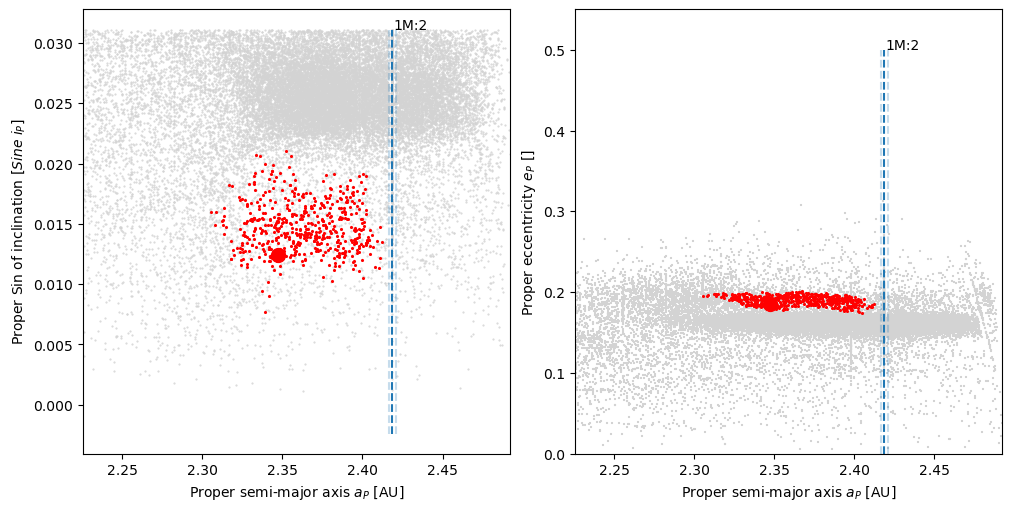

In [47]:
fig = plt.figure(figsize=(10, 5), layout="constrained")

spec = fig.add_gridspec(ncols=2, nrows=1)
ax1 = fig.add_subplot(spec[0, 0])
ax1.set_xlim(sma_range[0], sma_range[1])

ax1.scatter(data=neighbr_asteroids, x='a_P',y='sineI_P', marker=".", c='lightgrey', s=1)
ax1.scatter(data=ast_fam, x='a_P',y='sineI_P', edgecolors='red', marker="*", c='red', s=2)

luth_ie = ast_fam[ast_fam.ast_name == '27'][['a_P','sineI_P']].values

ax1.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)

ax1.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax1.set_ylabel("Proper Sin of inclination [$Sine ~i_P$]")

plot_mmrs(ax1, sma_range, inc_range[0], inc_range[1], min_strength=5e-13)

ax2 = fig.add_subplot(spec[0, 1])
ax2.set_xlim(sma_range[0], sma_range[1])
ax2.set_ylim(0.0, 0.55)
ax2.scatter(data=neighbr_asteroids, x='a_P',y='e_P', marker="+", c='lightgrey', s=1)
ax2.scatter(data=ast_fam, x='a_P',y='e_P', edgecolors='red', marker="*", c='red', s=2)

luth_ie = ast_fam[ast_fam.ast_name == '27'][['a_P','e_P']].values
ax2.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)
ax2.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax2.set_ylabel("Proper eccentricity $e_P$ []")
plot_mmrs(ax2, sma_range, 0.0, 0.5, min_strength=5e-13)

labels=[3.1,0.53,r'J']
#plot_crossing_e(ax2, jupiter_sma, jupiter_ecc, 3.0, 3.5, labels)
labels=[3.3,0.582,r'M']
#plot_crossing_e(ax2, mars_sma, mars_ecc, 3.0, 3.5, labels)

plt.savefig(plot_dir / "neighbour_aei.png", dpi=300)
plt.show()


5M:9:2.25412554 2.2551344600000003
7J:2:2.25576607 2.25657393
2E:7:2.30477901 2.30566099
1M:2:2.4164367999999996 2.4209432
5M:9:2.25412554 2.2551344600000003
7J:2:2.25576607 2.25657393
2E:7:2.30477901 2.30566099
1M:2:2.4164367999999996 2.4209432
5M:9:2.25412554 2.2551344600000003
7J:2:2.25576607 2.25657393
2E:7:2.30477901 2.30566099
1M:2:2.4164367999999996 2.4209432


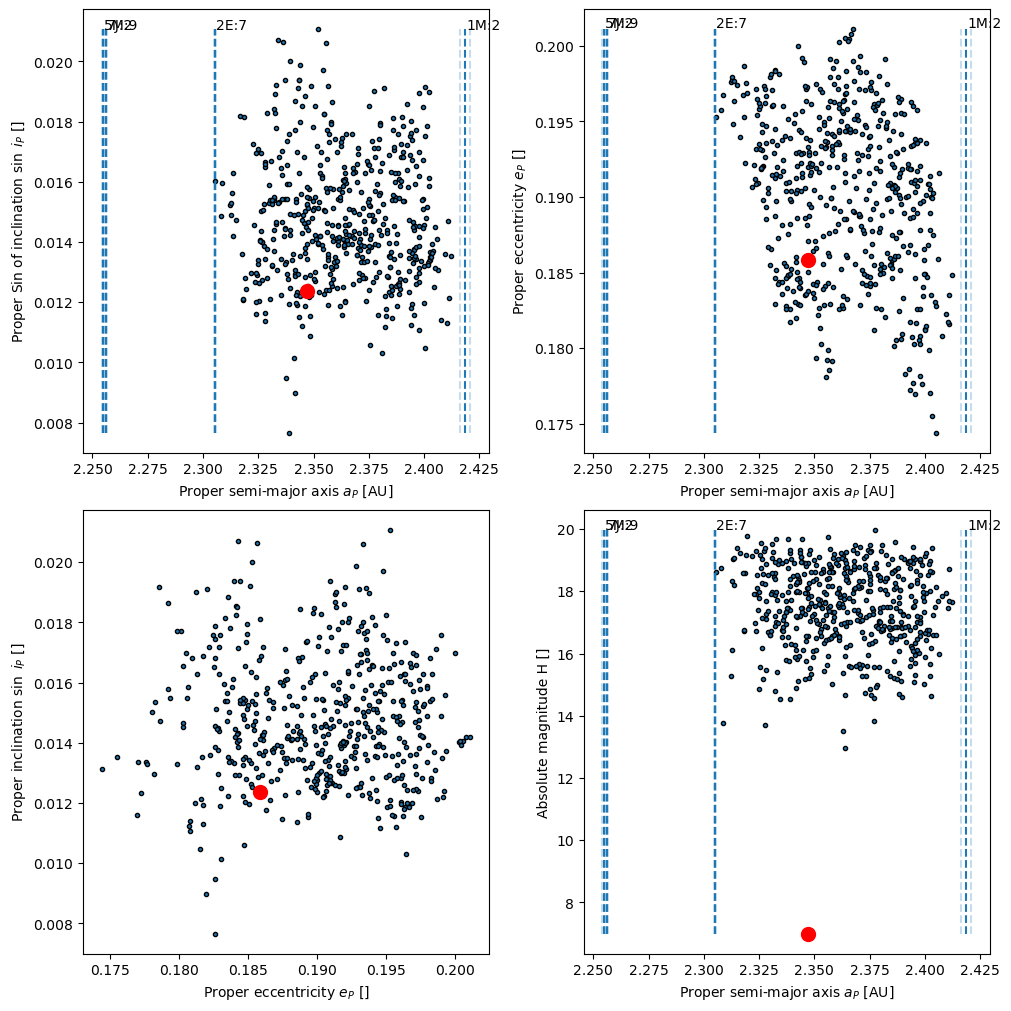

In [24]:
fig = plt.figure(figsize=(10, 10), layout="constrained")

spec = fig.add_gridspec(ncols=2, nrows=2)

ax1 = fig.add_subplot(spec[0, 0])
ax1.scatter(data=ast_fam, x='a_P',y='sineI_P', edgecolors='black', marker=".")
luth_ie = ast_fam[ast_fam.ast_name == '27'][['a_P','sineI_P']].values
ax1.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)
ax1.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax1.set_ylabel("Proper Sin of inclination $\sin ~i_P$ []")
plot_mmrs(ax1, sma_range, ast_fam.sineI_P.min(), ast_fam.sineI_P.max())

ax2 = fig.add_subplot(spec[0, 1])
ax2.scatter(data=ast_fam, x='a_P',y='e_P', edgecolors='black', marker=".")
luth_ie = ast_fam[ast_fam.ast_name == '27'][['a_P','e_P']].values
ax2.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)
ax2.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax2.set_ylabel("Proper eccentricity $e_P$ []")
plot_mmrs(ax2, sma_range, ast_fam.e_P.min(), ast_fam.e_P.max())

ax3 = fig.add_subplot(spec[1, 0])
plt.scatter(data=ast_fam, x='e_P',y='sineI_P' , edgecolors='black', marker=".")
luth_ie = ast_fam[ast_fam.ast_name == '27'][['e_P','sineI_P']].values
ax3.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)
ax3.set_xlabel("Proper eccentricity $e_P$ []")
ax3.set_ylabel("Proper inclination $\sin ~i_P$ []")

ax4 = fig.add_subplot(spec[1, 1])
ax4.scatter(data=ast_fam, x='a_P',y='abs_mag' , edgecolors='black', marker=".")
luth_ie = ast_fam[ast_fam.ast_name == '27'][['a_P','abs_mag']].values
ax4.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)
ax4.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax4.set_ylabel("Absolute magnitude H []")
plot_mmrs(ax4, sma_range, ast_fam.abs_mag.min(), ast_fam.abs_mag.max())

plt.savefig(plot_dir / "proper_ieM.png", dpi=300)
plt.show()


5M:9:2.25412554 2.2551344600000003
7J:2:2.25576607 2.25657393
2E:7:2.30477901 2.30566099
1M:2:2.4164367999999996 2.4209432
5M:9:2.25412554 2.2551344600000003
7J:2:2.25576607 2.25657393
2E:7:2.30477901 2.30566099
1M:2:2.4164367999999996 2.4209432


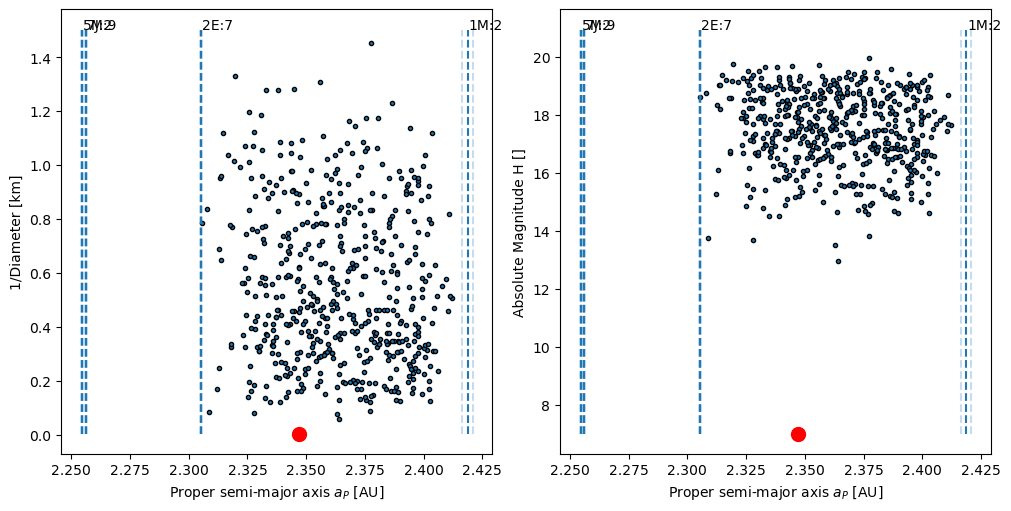

In [26]:
fig = plt.figure(figsize=(10, 5), layout="constrained")

spec = fig.add_gridspec(ncols=2, nrows=1)
ax1 = fig.add_subplot(spec[0, 0])

over_D = 1/ast_fam.diam

ax1.scatter(x=ast_fam.a_P,y=over_D, edgecolors='black', marker=".")
luth_ie = ast_fam[ast_fam.ast_name == '27'][['a_P','diam']].values
ax1.plot(luth_ie[0][0],1/luth_ie[0][1], 'ro', markersize=10)
ax1.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax1.set_ylabel("1/Diameter [km]")
plot_mmrs(ax1, sma_range, over_D.min(), over_D.max()+0.05)

ax2 = fig.add_subplot(spec[0, 1])
ax2.scatter(x=ast_fam.a_P,y=ast_fam.abs_mag , edgecolors='black', marker=".")
luth_ie = ast_fam[ast_fam.ast_name == '27'][['a_P','abs_mag']].values
ax2.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)
ax2.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax2.set_ylabel("Absolute Magnitude H []")
plot_mmrs(ax2, sma_range, ast_fam.abs_mag.min(), ast_fam.abs_mag.max()+1)

plt.savefig(f"../plots/proper_DM.png", dpi=300)
plt.show()


In [28]:
brights = ast_fam[ast_fam['abs_mag']<13]

brights

,ast_name,abs_mag,a_P,e_P,sineI_P,n,g,s,lyap_time,My_int_time,irad,ideg,diam
0,27,7.00,2.347023,0.185856,0.012377,100.10790,38.563487,-43.614894,69.0,-10,0.012378,0.709197,268.948730
1,3014,12.96,2.364047,0.190990,0.014800,99.02831,39.271388,-44.739552,149.3,-10,0.014801,0.848008,17.285005


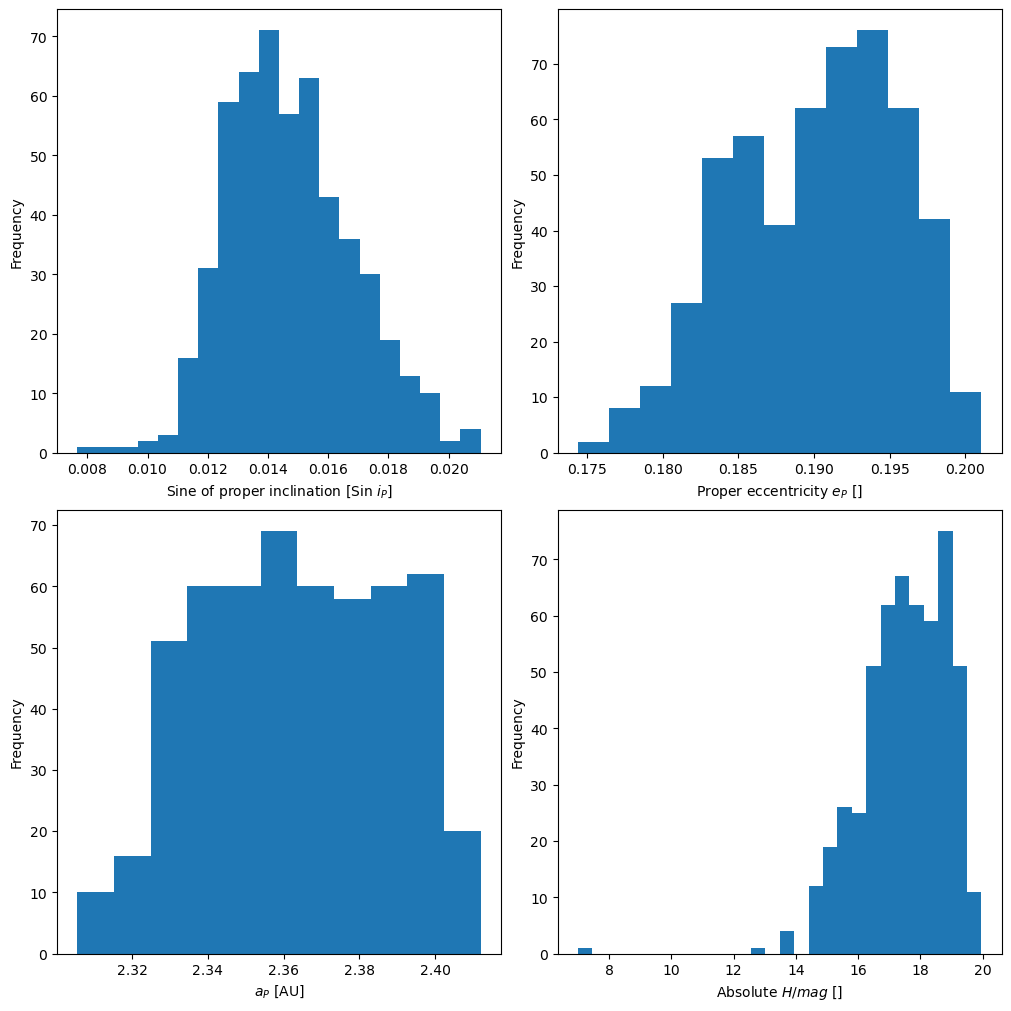

In [29]:
y_label = "Frequency"

fig = plt.figure(figsize=(10, 10), layout="constrained")

spec = fig.add_gridspec(ncols=2, nrows=2)

ax1 = fig.add_subplot(spec[0, 0])
ax1.hist(data=ast_fam, x='sineI_P', bins='auto')
ax1.set_ylabel(y_label)
ax1.set_xlabel("Sine of proper inclination [Sin $i_P$]")

ax2 = fig.add_subplot(spec[0, 1])
ax2.hist(data=ast_fam, x='e_P', bins='auto')
ax2.set_ylabel(y_label)
ax2.set_xlabel("Proper eccentricity $e_P$ []")

ax3 = fig.add_subplot(spec[1, 0])
ax3.hist(data=ast_fam, x='a_P', bins='auto')
ax3.set_ylabel(y_label)
ax3.set_xlabel("$a_P$ [AU]")

ax4 = fig.add_subplot(spec[1, 1])
ax4.hist(data=ast_fam, x='abs_mag' , bins='auto')
ax4.set_ylabel(y_label)
ax4.set_xlabel("Absolute $H / mag$ []")

plt.savefig(plot_dir / "proper_hist.png", dpi=300)

plt.show()

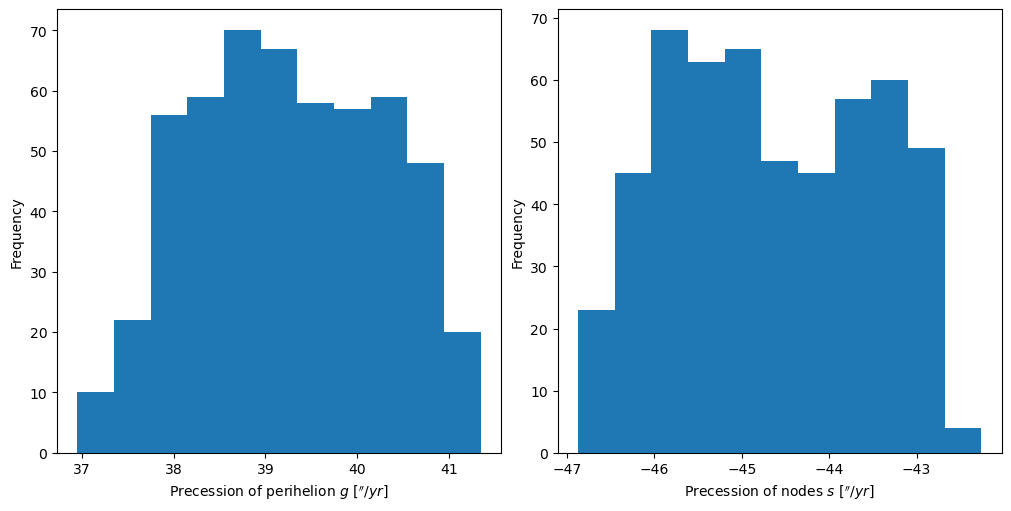

In [30]:
fig = plt.figure(figsize=(10, 5), layout="constrained")

spec = fig.add_gridspec(ncols=2, nrows=1)
ax1 = fig.add_subplot(spec[0, 0])

ax1.hist(data=ast_fam, x='g', bins='auto')
ax1.set_ylabel("Frequency")
ax1.set_xlabel("Precession of perihelion $g$ [$''/yr$]")

ax2 = fig.add_subplot(spec[0, 1])

ax2.hist(data=ast_fam, x='s', bins='auto')
ax2.set_ylabel("Frequency")
ax2.set_xlabel("Precession of nodes $s$ [$''/yr$]")

plt.savefig(plot_dir / "proper_gs.png", dpi=300)
plt.show()

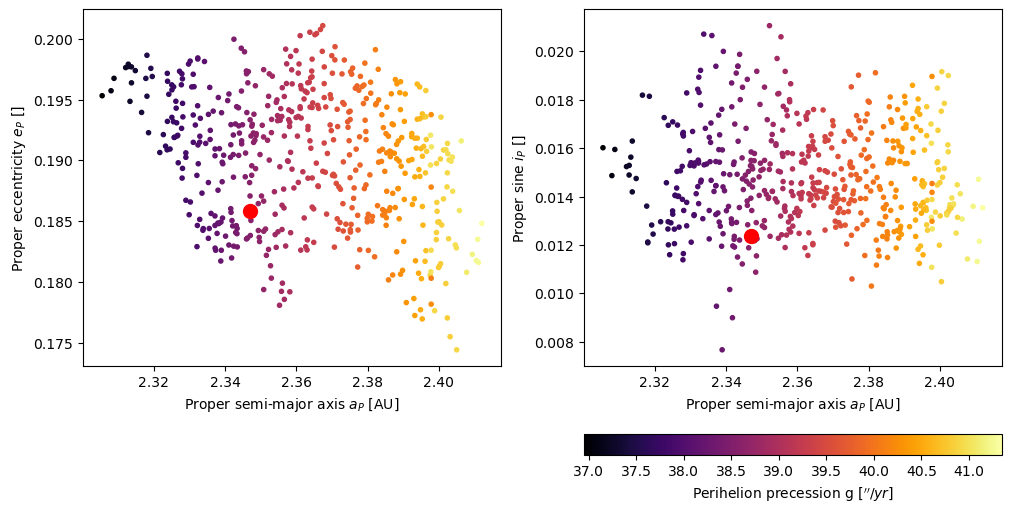

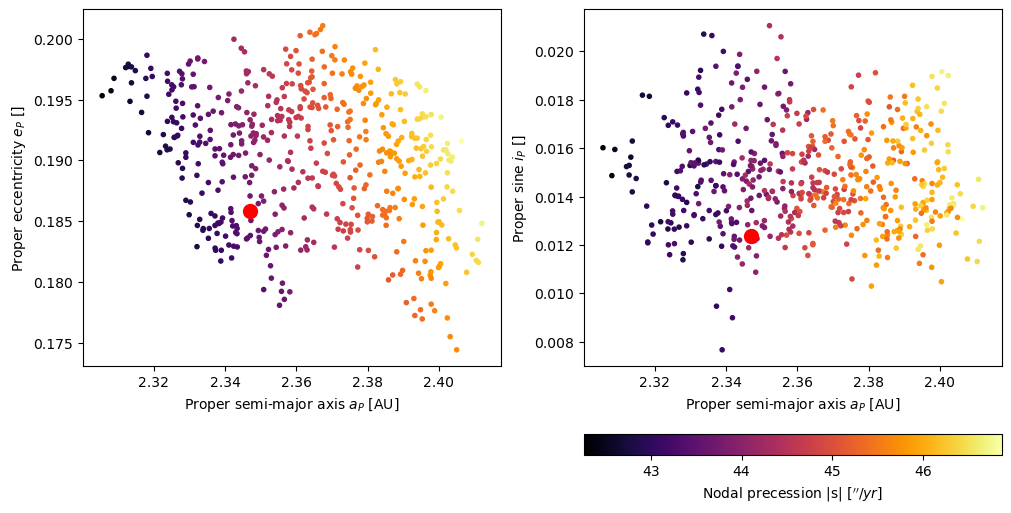

In [31]:
fig = plt.figure(figsize=(10, 5), layout="constrained")

spec = fig.add_gridspec(ncols=2, nrows=1)
ax1 = fig.add_subplot(spec[0, 0])

cm_yr = mpl.colormaps['inferno'] 
colour_values = ast_fam['g']

esc = ax1.scatter(data=ast_fam, x='a_P',y='e_P', edgecolors=None, marker=".",c=colour_values, cmap = cm_yr)
luth_ie = ast_fam[ast_fam.ast_name == '27'][['a_P','e_P']].values
ax1.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)
ax1.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax1.set_ylabel("Proper eccentricity $e_P$ []")

ax2 = fig.add_subplot(spec[0, 1])
esc = ax2.scatter(data=ast_fam, x='a_P',y='sineI_P', edgecolors=None, marker=".",c=colour_values, cmap = cm_yr)
luth_ie = ast_fam[ast_fam.ast_name == '27'][['a_P','sineI_P']].values
ax2.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)
ax2.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax2.set_ylabel("Proper sine $i_P$ []")

fig.colorbar(esc, label="Perihelion precession g [$\'' / yr$]", location='bottom')
plt.savefig(plot_dir / "proper_aei_g.png", dpi=300)
plt.show()

fig = plt.figure(figsize=(10, 5), layout="constrained")
spec = fig.add_gridspec(ncols=2, nrows=1)

ax1 = fig.add_subplot(spec[0, 0])
cm_yr = mpl.colormaps['inferno'] 
colour_values = np.absolute(ast_fam['s'])

esc = ax1.scatter(data=ast_fam, x='a_P',y='e_P', edgecolors=None, marker=".",c=colour_values, cmap = cm_yr)
luth_ie = ast_fam[ast_fam.ast_name == '27'][['a_P','e_P']].values
ax1.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)
ax1.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax1.set_ylabel("Proper eccentricity $e_P$ []")

ax2 = fig.add_subplot(spec[0, 1])
esc = ax2.scatter(data=ast_fam, x='a_P',y='sineI_P', edgecolors=None, marker=".",c=colour_values, cmap = cm_yr)
luth_ie = ast_fam[ast_fam.ast_name == '27'][['a_P','sineI_P']].values
ax2.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)
ax2.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax2.set_ylabel("Proper sine $i_P$ []")

plt.colorbar(esc, label="Nodal precession |s| [$\'' / yr$]", location='bottom')
plt.savefig(plot_dir / "proper_aie_s.png", dpi=300)
plt.show()


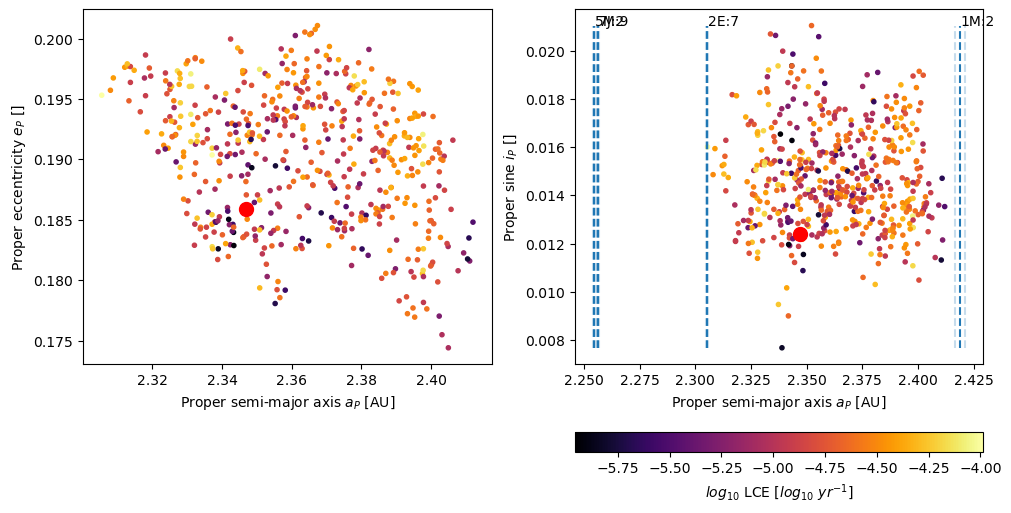

In [48]:
# Get the log(1/lyap_time)
log_lce = np.log10(1/(ast_fam.lyap_time*1e3))

fig = plt.figure(figsize=(10, 5), layout="constrained")
spec = fig.add_gridspec(ncols=2, nrows=1)

ax1 = fig.add_subplot(spec[0, 0])
cm_yr = mpl.colormaps['inferno'] 
colour_values = log_lce

esc = ax1.scatter(data=ast_fam, x='a_P',y='e_P', edgecolors=None, marker=".",c=colour_values, cmap = cm_yr)
luth_ie = ast_fam[ast_fam.ast_name == '27'][['a_P','e_P']].values
ax1.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)
ax1.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax1.set_ylabel("Proper eccentricity $e_P$ []")

ax2 = fig.add_subplot(spec[0, 1])
esc = ax2.scatter(data=ast_fam, x='a_P',y='sineI_P', marker=".",c=colour_values, cmap = cm_yr)
luth_ie = ast_fam[ast_fam.ast_name == '27'][['a_P','sineI_P']].values
ax2.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)
ax2.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax2.set_ylabel("Proper sine $i_P$ []")
plot_mmrs(ax2, sma_range, ast_fam.sineI_P.min(), ast_fam.sineI_P.max())

plt.colorbar(esc, label="$log_{10}$ LCE [$log_{10} ~yr^{-1}$]", location='bottom')
plt.savefig(plot_dir / "proper_aie_lce.png", dpi=300)
plt.show()


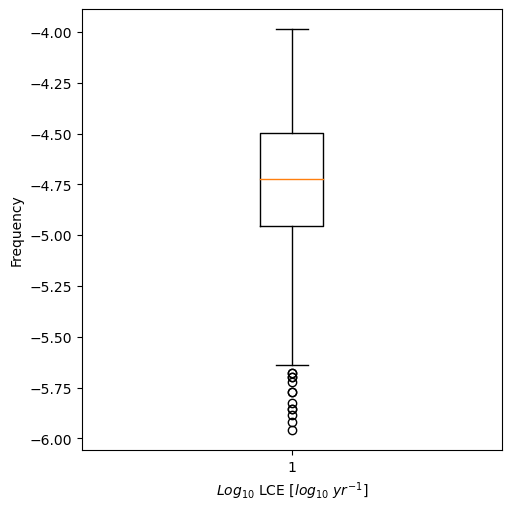

In [36]:
fig = plt.figure(figsize=(5, 5), layout="constrained")

spec = fig.add_gridspec(ncols=1, nrows=1)
ax1 = fig.add_subplot(spec[0, 0])

ax1.boxplot(x=log_lce)
ax1.set_ylabel("Frequency")
ax1.set_xlabel("$Log_{10}$ LCE [$log_{10} ~yr^{-1}$]")
plt.show()

In [37]:
# Estimate the mean motion of a body for a given sma
def n_value(semi_major_axis):
    orbital_p = semi_major_axis**(3/2)
    return (360/orbital_p)

def sma_value(mean_motion):
    orbital_p = 360/mean_motion
    return orbital_p**(2/3)

def nplot_2b_mmr(ax, n_range, y_min, y_max, min_strength=1e-13, y_offset=0.98):
    plt_2b_mmr = mmr_atlas[(mmr_atlas.sma >= sma_value(n_range[1])) & (mmr_atlas.sma <= sma_value(n_range[0])) & 
                            (mmr_atlas.strength > min_strength)]    
    
    for _, mmr in plt_2b_mmr.iterrows():
        label = f"{mmr.ratio1}{mmr.planet[0]}:{mmr.ratio2}"
        if mmr.sma-mmr.width > sma_value(n_range[0]):
            ax.vlines(n_value(mmr.sma-mmr.width), y_min, y_max, linestyles='dashed', alpha=0.25)
        ax.vlines(n_value(mmr.sma), y_min, y_max, linestyles='dashed')
        if mmr.sma+mmr.width < sma_value(n_range[0]):
            ax.vlines(n_value(mmr.sma+mmr.width), y_min, y_max, linestyles='dashed', alpha=0.25)
        ax.text(n_value(mmr.sma), (y_max)*y_offset, label)


def nplot_3b_mmr(ax, n_range, y_min, y_max, y_offset=0.98):
    for mmr_nme, sma in mmrs_3b_luthera.items():
        if n_value(sma[0]) < n_range[0] or n_value(sma[0]) > n_range[1]:
            continue
        ax.vlines(n_value(sma[0]), y_min, y_max, linestyles='dashed')
        ax.text(n_value(sma[1]), y_max * y_offset, mmr_nme,rotation=90)

# add the MMR lines in a plot with an mean motion (n) on x axis.
def nplot_mmrs(ax, n_range, y_min, y_max, y_offset=0.9):
    nplot_2b_mmr(ax, n_range, y_min, y_max)
    nplot_3b_mmr(ax, n_range, y_min, y_max)


# Secular resonances map
sec_res_list = [[saturn_g6, r'$\nu_{6}$'],
           [2*saturn_g6-jupiter_g5, '$g-2g_6+g_5$'], 
           [3*saturn_g6-2*jupiter_g5, '$g-3g_6+2g_5$']]

# Plot the secular resonances


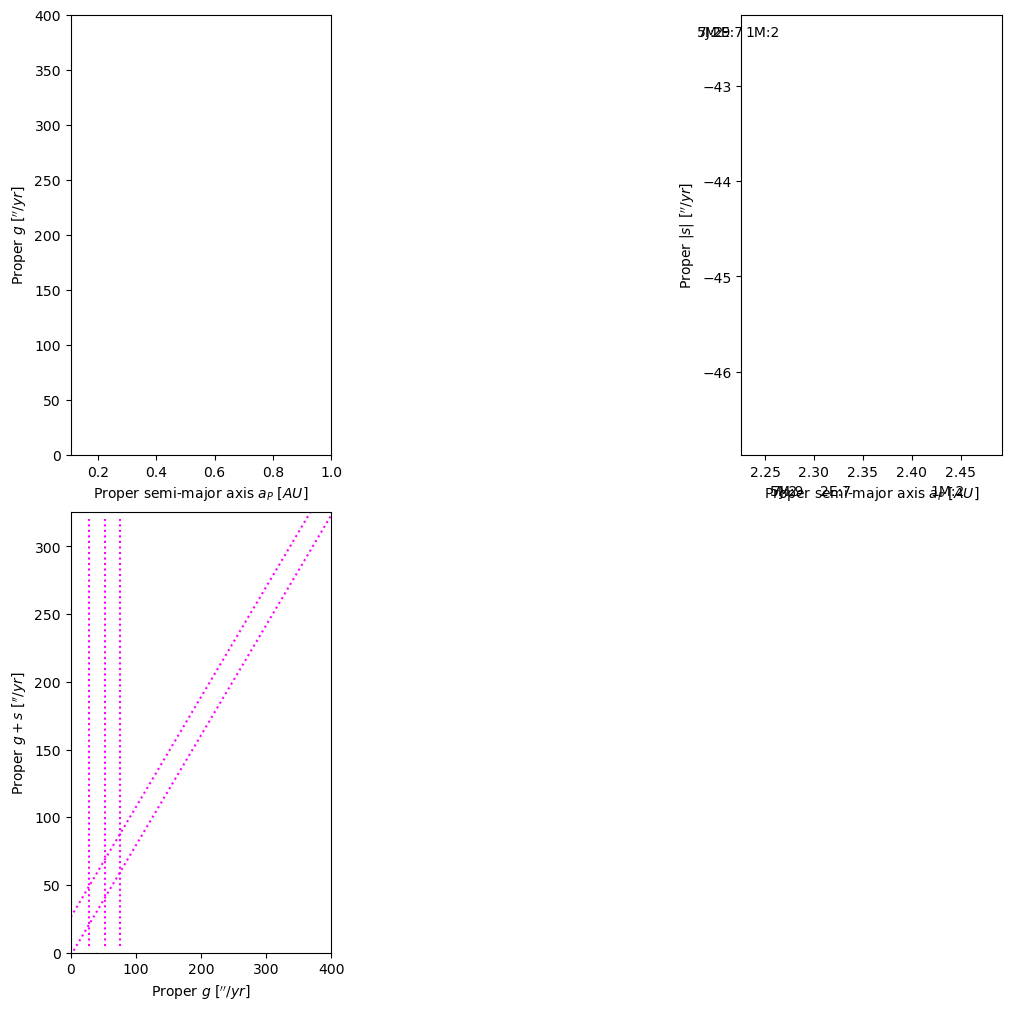

In [46]:
s_range = (ast_fam.s.min(), ast_fam.s.max())
fig = plt.figure(figsize=(10, 10), layout="constrained")

spec = fig.add_gridspec(ncols=2, nrows=2)
ax1 = fig.add_subplot(spec[0, 1])

ax1.set_xlim(sma_range)
ax1.set_ylim(s_range)

ax1.scatter(x=ast_fam.a_P,y=np.absolute(ast_fam.s), edgecolors='black', marker=".")
luth_ie = ast_fam[ast_fam.ast_name == '27'][['a_P','s']].values
ax1.plot(luth_ie[0][0],np.absolute(luth_ie[0][1]), 'ro', markersize=10)
# plot the MMR in n space
plot_mmrs(ax1, sma_range, s_range[0], s_range[1]-5)

# Plot the secular non-linear
ax1.hlines(-saturn_s6-jupiter_g5+saturn_g6,sma_range[0],sma_range[1],linestyles='dotted', colors='magenta')
# ax1.text(3.18, 50.7, r'$s-s_6-g_5+g_6$')

ax1.set_xlabel("Proper semi-major axis $a_P$ [$AU$]")
ax1.set_ylabel("Proper $|s|$ [$''/yr$]")

ax2 = fig.add_subplot(spec[0, 0])
# spec the x and y axes limits
ax2.set_xlim(a_range)
ax2.set_ylim((0, 400))

ax2.scatter(x=ast_fam.a_P,y=ast_fam.g, edgecolors='black', marker=".")
luth_ie = ast_fam[ast_fam.ast_name == '27'][['a_P','g']].values
ax2.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)
ax2.set_xlabel("Proper semi-major axis $a_P$ [$AU$]")
ax2.set_ylabel("Proper $g$ [$''/yr$]")

# Plot the secular resonances
for sec_res in sec_res_list: 
    ax2.hlines(sec_res[0], sma_range[0], sma_range[1], linestyles='dotted', color='magenta')
    # ax2.text(3.18, sec_res[0]*1.08,  sec_res[1])

# plot the MMR in a space
plot_mmrs(ax2, sma_range, 10, 380)

ax3 = fig.add_subplot(spec[1, 0])

# spec the x and y axes limits
s_range = (40, 95)
g_range = (0, 400)
gs_range = (0, 325)
ax3.set_xlim(g_range)
ax3.set_ylim(gs_range)
g_s = ast_fam.g+ast_fam.s
ax3.scatter(x=ast_fam.g,y=g_s, edgecolors='black', marker=".")
luth_ie = ast_fam[ast_fam.ast_name == '27'][['g','s']].values
ax3.plot(luth_ie[0][0],luth_ie[0][0]+luth_ie[0][1], 'ro', markersize=10)

# v_6 
ax3.vlines(sec_res_list[0][0], 5, 320, linestyles='dotted', colors='magenta')
#ax3.text(28, 250, sec_res_list[0][1],rotation=90)
# g-2g_6+g_5
ax3.vlines(sec_res_list[1][0], 5, 320, linestyles='dotted', colors='magenta')
#ax3.text(55, 250, sec_res_list[1][1],rotation=90)
# g-3g_6+2g_5
ax3.vlines(sec_res_list[2][0], 5, 320, linestyles='dotted', colors='magenta')
#ax3.text(78, 250, sec_res_list[2][1],rotation=90)
# s-s_6
g_vals = np.linspace(g_range[0],g_range[1], 100)
gs_vals = np.linspace(gs_range[0],gs_range[1], 100)
ax3.plot(g_vals, gs_vals-saturn_s6, ls='dotted', c='magenta')
#ax3.text(250, 250, r'$\nu_{16}$')
# s-s_6-g_5+g_6
g_vals = np.linspace(g_range[0],g_range[1], 100)
gs_vals = np.linspace(gs_range[0],gs_range[1], 100)
ax3.plot(g_vals, gs_vals-saturn_g6-saturn_s6, ls='dotted', c='magenta')
#ax3.text(250, 280, r'$g + s - g_6 - s_6$')

ax3.set_xlabel("Proper $g$ [$''/yr$]")
ax3.set_ylabel("Proper $g+s$ [$''/yr$]")

plt.savefig(plot_dir / "proper_ags.png", dpi=300)
plt.show()